# Hồi quy tuyến tính, đa thức và logistic

Tài liệu ôn tập dựa trên bài giảng **Hồi quy** của ThS. Lê Minh Tân
và nối trực tiếp sang Phụ lục B của đồ án:

1. **Linear Regression & OLS (slides 3–12, ví dụ trang 19):** đường khớp tốt nhất, các đoạn phần dư dọc $\varepsilon_i = y_i - \hat{y}_i$, và nghiệm đóng $\hat{\beta} = (X^T X)^{-1} X^T y$.
2. **Polynomial Regression (slides 13–14):** ma trận thiết kế bậc $m$, từ underfit ($m=1$) đến **bẫy overfit** khi $m = n - 1$.
3. **Logistic Regression (slides 15–18):** hàm Sigmoid $f(x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x)}}$ và hàm mất mát **Binary Cross-Entropy (Log Loss)**.
4. **Liên hệ PAPI × STING (Phụ lục B):** đọc lại `sup_ridge.joblib` và `sup_classifier.joblib` trên holdout 2023→2024 (`59` tỉnh), vẽ trực tiếp phần dư Ridge, Sigmoid của Logistic trên nhãn STING (`0 = nhiễu −1`, `1 = vùng dày`), và giải thích vì sao Ridge giảm MAE nhưng chiếu lên lưới STING vẫn bỏ sót `11/11` tỉnh nhiễu.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss, mean_absolute_error, mean_squared_error, r2_score

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "sting.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook trong repo có src/sting.py")
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

from scripts.common.fig_style import PALETTE, style_context
from scripts.common.papi_pred_common import REGRESSION_FEATURES, load_config, load_panel
from scripts.supervised.predict_supervised import build_classification_pairs, build_regression_pairs

plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
print("Đã nạp thư viện và kết nối repo.")

Đã nạp thư viện và kết nối repo.


## 1. Linear Regression (OLS) và các đoạn phần dư $\varepsilon_i$ (bài giảng, trang 3–12 và 19)

Dùng đúng bảng 6 điểm ở slide 19: `(1.5, -0.96), (2.0, -2.71), (3.5, -3.13), (5.0, 2.26), (6.5, 3.45), (7.0, 2.06)`.
Ta tự tính nghiệm bình phương tối thiểu $\hat{\beta} = (X^T X)^{-1} X^T y$ rồi đối chiếu với `LinearRegression`,
đồng thời vẽ rõ 6 đoạn phần dư dọc $\varepsilon_i$ như trên slide.

Nghiệm đóng OLS: y = -4.0613 + 0.9936·x | MSE = 2.1864 | R² = 0.6650


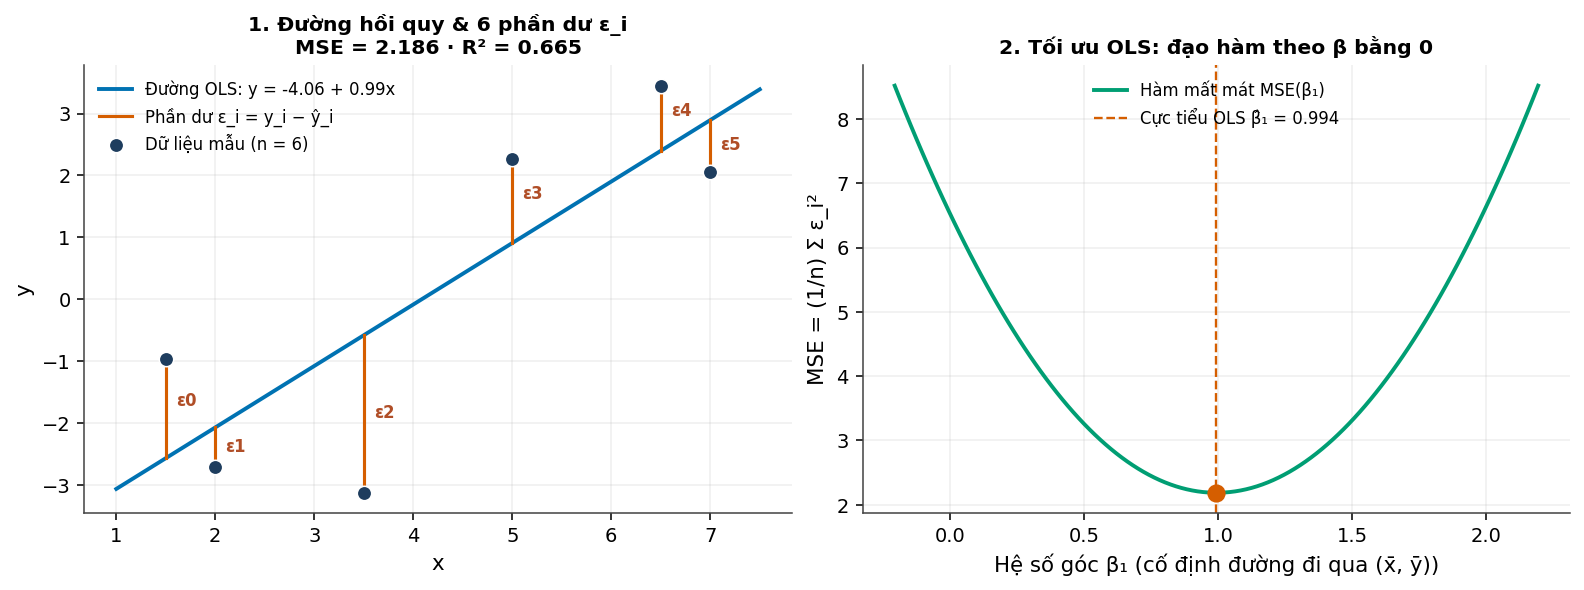

In [2]:
x_demo = np.array([1.5, 2.0, 3.5, 5.0, 6.5, 7.0])
y_demo = np.array([-0.96, -2.71, -3.13, 2.26, 3.45, 2.06])

X_design = np.column_stack([np.ones_like(x_demo), x_demo])
beta_ols = np.linalg.inv(X_design.T @ X_design) @ (X_design.T @ y_demo)
lr_demo = LinearRegression().fit(x_demo[:, None], y_demo)
np.testing.assert_allclose(beta_ols, [lr_demo.intercept_, lr_demo.coef_[0]], atol=1e-10)

y_hat = X_design @ beta_ols
eps = y_demo - y_hat
mse_demo = float(np.mean(eps ** 2))
r2_demo = float(r2_score(y_demo, y_hat))
print(f"Nghiệm đóng OLS: y = {beta_ols[0]:.4f} + {beta_ols[1]:.4f}·x | MSE = {mse_demo:.4f} | R² = {r2_demo:.4f}")

with style_context():
    fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(11.2, 4.1), dpi=140, layout="constrained")
    xx = np.linspace(1.0, 7.5, 100)
    ax_l.plot(xx, beta_ols[0] + beta_ols[1] * xx, "-", color=PALETTE["blue"], lw=2.0,
              label=f"Đường OLS: y = {beta_ols[0]:.2f} + {beta_ols[1]:.2f}x", zorder=2)
    for i, (xi, yi, ypi, ei) in enumerate(zip(x_demo, y_demo, y_hat, eps, strict=True)):
        ax_l.plot([xi, xi], [ypi, yi], "-", color="#D55E00", lw=1.6,
                  label="Phần dư ε_i = y_i − ŷ_i" if i == 0 else None, zorder=3)
        dy_off = 0.28 if ei >= 0 else -0.45
        ax_l.text(xi + 0.10, (yi + ypi) / 2 + dy_off * 0.15, f"ε{i}", fontsize=8.5, color="#B04E27", fontweight="bold")
    ax_l.scatter(x_demo, y_demo, s=55, color="#1E3D5E", edgecolors="white", linewidths=0.8, label="Dữ liệu mẫu (n = 6)", zorder=4)
    ax_l.set_xlabel("x")
    ax_l.set_ylabel("y")
    ax_l.set_title(f"1. Đường hồi quy & 6 phần dư ε_i\nMSE = {mse_demo:.3f} · R² = {r2_demo:.3f}", fontsize=10.5)
    ax_l.grid(alpha=0.2)
    ax_l.legend(loc="upper left", fontsize=8.5, framealpha=0.92)

    slopes = np.linspace(beta_ols[1] - 1.2, beta_ols[1] + 1.2, 120)
    mse_curve = [float(np.mean((y_demo - (y_demo.mean() + b1 * (x_demo - x_demo.mean()))) ** 2)) for b1 in slopes]
    ax_r.plot(slopes, mse_curve, "-", color=PALETTE["green"], lw=2.0, label="Hàm mất mát MSE(β₁)")
    ax_r.axvline(beta_ols[1], color="#D55E00", linestyle="--", lw=1.2, label=f"Cực tiểu OLS β̂₁ = {beta_ols[1]:.3f}")
    ax_r.scatter([beta_ols[1]], [mse_demo], s=70, color="#D55E00", zorder=4)
    ax_r.set_xlabel("Hệ số góc β₁ (cố định đường đi qua (x̄, ȳ))")
    ax_r.set_ylabel("MSE = (1/n) Σ ε_i²")
    ax_r.set_title("2. Tối ưu OLS: đạo hàm theo β bằng 0", fontsize=10.5)
    ax_r.grid(alpha=0.2)
    ax_r.legend(loc="upper center", fontsize=8.5, framealpha=0.92)
    plt.show()

## 2. Polynomial Regression: từ Underfit đến Bẫy Overfit (bài giảng, trang 13–14)

Dựng ma trận thiết kế bậc $m$: $X' = [1, x, x^2, \dots, x^m]$ và giải $\hat{\beta} = (X'^T X')^{-1} X'^T y$.
Với $n = 6$ điểm, đa thức bậc $m = 5$ có đúng 6 tham số nên đi qua khít cả 6 điểm (MSE trên train bằng `0`),
nhưng đường cong uốn lượn gắt ở vùng biên — minh họa trực quan lý do không ép đa thức bậc cao trên PAPI ít mẫu.

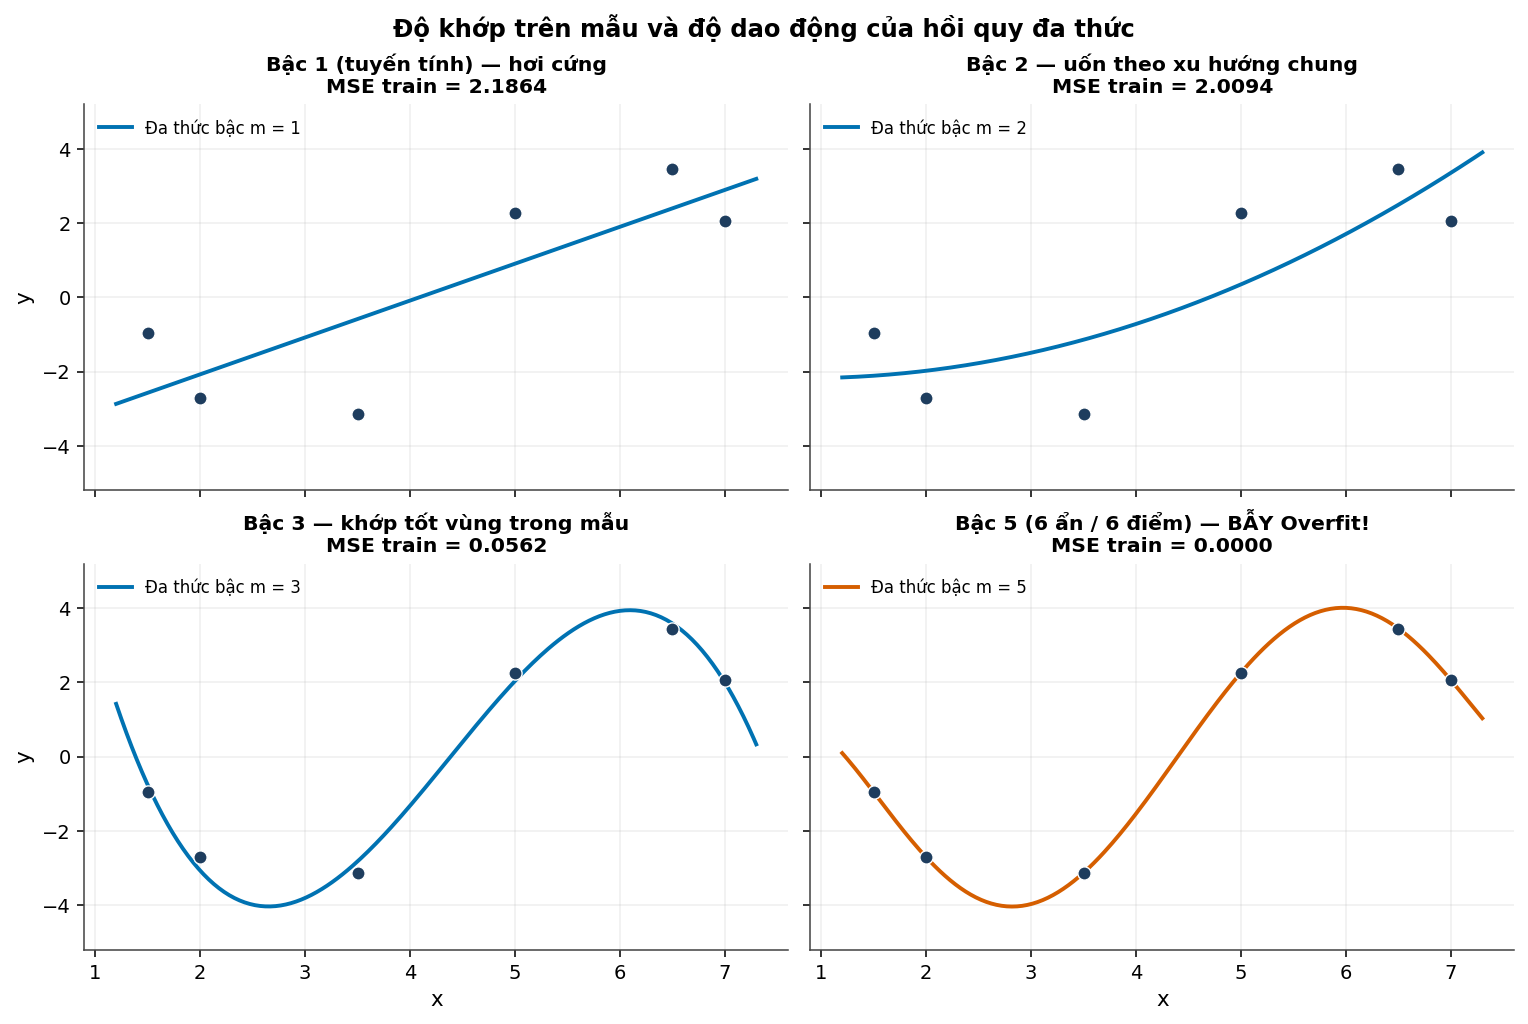

In [3]:
degrees = (1, 2, 3, 5)
notes_deg = {
    1: "Bậc 1 (tuyến tính) — hơi cứng",
    2: "Bậc 2 — uốn theo xu hướng chung",
    3: "Bậc 3 — khớp tốt vùng trong mẫu",
    5: "Bậc 5 (6 ẩn / 6 điểm) — BẪY Overfit!",
}
x_dense = np.linspace(1.2, 7.3, 250)

with style_context():
    fig, axes = plt.subplots(2, 2, figsize=(10.8, 7.2), dpi=140, sharex=True, sharey=True, layout="constrained")
    for ax, deg in zip(axes.ravel(), degrees, strict=True):
        X_poly = np.column_stack([x_demo ** p for p in range(deg + 1)])
        beta_p = np.linalg.solve(X_poly.T @ X_poly, X_poly.T @ y_demo)
        y_fit_tr = X_poly @ beta_p
        mse_p = float(mean_squared_error(y_demo, y_fit_tr))
        X_grid = np.column_stack([x_dense ** p for p in range(deg + 1)])
        y_curve = X_grid @ beta_p

        col = "#D55E00" if deg == 5 else PALETTE["blue"]
        ax.plot(x_dense, y_curve, "-", color=col, lw=2.0, label=f"Đa thức bậc m = {deg}")
        ax.scatter(x_demo, y_demo, s=46, color="#1E3D5E", edgecolors="white", linewidths=0.7, zorder=4)
        ax.set_title(f"{notes_deg[deg]}\nMSE train = {mse_p:.4f}", fontsize=10.5)
        ax.grid(alpha=0.2)
        ax.legend(loc="upper left", fontsize=8.5, framealpha=0.92)
    axes[0, 0].set_ylim(-5.2, 5.2)
    for ax in axes[1, :]:
        ax.set_xlabel("x")
    for ax in axes[:, 0]:
        ax.set_ylabel("y")
    fig.suptitle("Độ khớp trên mẫu và độ dao động của hồi quy đa thức", fontsize=12.5)
    plt.show()

## 3. Logistic Regression: Sigmoid & Binary Cross-Entropy (bài giảng, trang 15–18)

Logistic Regression đưa tổ hợp tuyến tính $z = \beta_0 + \beta_1 x$ qua hàm Sigmoid
$f(x) = \frac{1}{1 + e^{-z}} \in (0, 1)$ để ước lượng xác suất $P(y = 1 \mid x)$ và tối thiểu hóa
hàm mất mát **Binary Cross-Entropy (Log Loss)**:
$$L_{\text{BCE}} = -\frac{1}{M}\sum_{i=1}^{M}\left[y_i \ln f(x_i) + (1 - y_i)\ln(1 - f(x_i))\right].$$

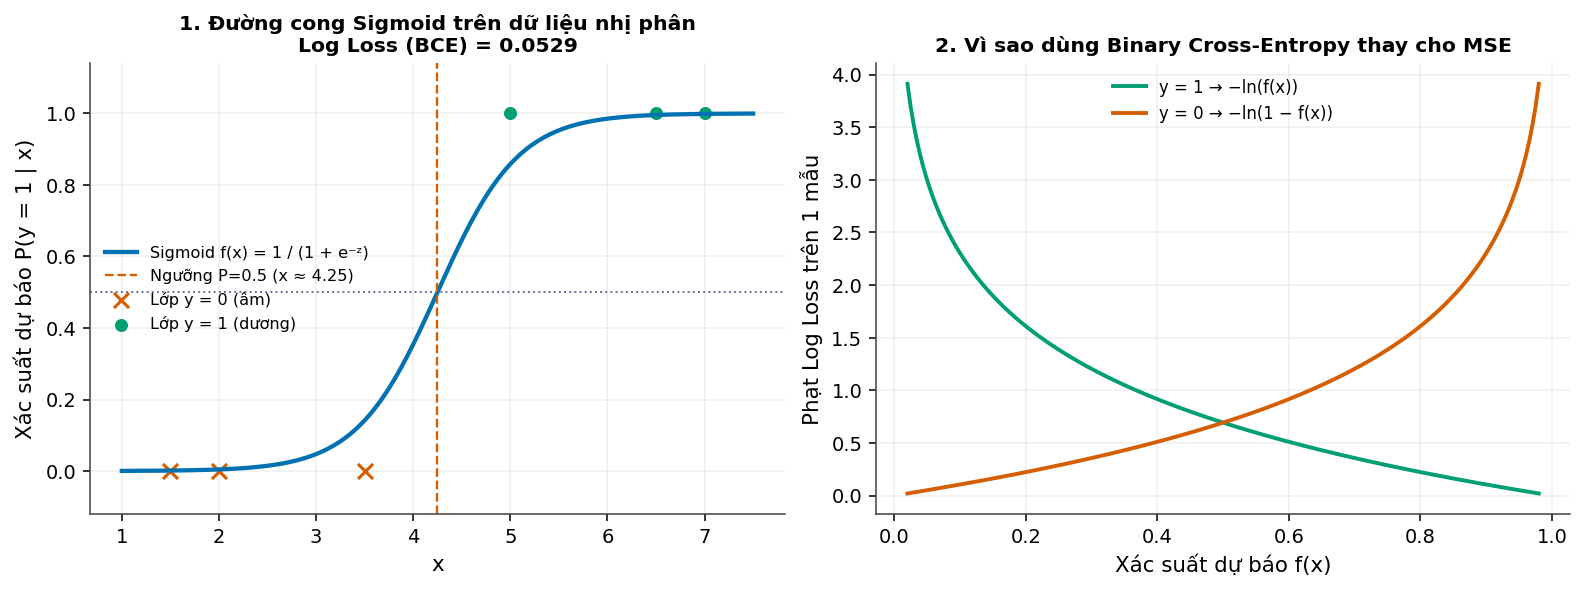

In [4]:
y_bin = (y_demo > 0).astype(int)
clf_demo = LogisticRegression(C=10.0, max_iter=1000).fit(x_demo[:, None], y_bin)
xx_s = np.linspace(1.0, 7.5, 200)
pp_s = clf_demo.predict_proba(xx_s[:, None])[:, 1]
bce_demo = float(log_loss(y_bin, clf_demo.predict_proba(x_demo[:, None])[:, 1]))
x_bound = float(-clf_demo.intercept_[0] / clf_demo.coef_[0, 0])

with style_context():
    fig, (ax_sig, ax_bce) = plt.subplots(1, 2, figsize=(11.2, 4.1), dpi=140, layout="constrained")
    ax_sig.plot(xx_s, pp_s, "-", color=PALETTE["blue"], lw=2.2, label="Sigmoid f(x) = 1 / (1 + e⁻ᶻ)")
    ax_sig.axhline(0.5, color="#64748B", linestyle=":", lw=1.0)
    ax_sig.axvline(x_bound, color="#D55E00", linestyle="--", lw=1.2, label=f"Ngưỡng P=0.5 (x ≈ {x_bound:.2f})")
    ax_sig.scatter(x_demo[y_bin == 0], y_bin[y_bin == 0], s=60, color="#D55E00", marker="x", lw=1.6, label="Lớp y = 0 (âm)")
    ax_sig.scatter(x_demo[y_bin == 1], y_bin[y_bin == 1], s=55, color=PALETTE["green"], edgecolors="white", lw=0.7, label="Lớp y = 1 (dương)")
    ax_sig.set_ylim(-0.12, 1.14)
    ax_sig.set_xlabel("x")
    ax_sig.set_ylabel("Xác suất dự báo P(y = 1 | x)")
    ax_sig.set_title(f"1. Đường cong Sigmoid trên dữ liệu nhị phân\nLog Loss (BCE) = {bce_demo:.4f}", fontsize=10.5)
    ax_sig.grid(alpha=0.2)
    ax_sig.legend(loc="center left", fontsize=8.3, framealpha=0.92)

    p_vals = np.linspace(0.02, 0.98, 200)
    ax_bce.plot(p_vals, -np.log(p_vals), "-", color=PALETTE["green"], lw=2.0, label="y = 1 → −ln(f(x))")
    ax_bce.plot(p_vals, -np.log(1.0 - p_vals), "-", color="#D55E00", lw=2.0, label="y = 0 → −ln(1 − f(x))")
    ax_bce.set_xlabel("Xác suất dự báo f(x)")
    ax_bce.set_ylabel("Phạt Log Loss trên 1 mẫu")
    ax_bce.set_title("2. Vì sao dùng Binary Cross-Entropy thay cho MSE", fontsize=10.5)
    ax_bce.grid(alpha=0.2)
    ax_bce.legend(loc="upper center", fontsize=8.5, framealpha=0.92)
    plt.show()

## 4. Liên hệ trực tiếp trên dữ liệu PAPI × STING (Phụ lục B đồ án)

Thay vì hồi quy OLS không phạt (dễ overfit với 8 chỉ tiêu có đa cộng tuyến nhẹ), đồ án chọn **Ridge**
(OLS + phạt $L_2 = \alpha \|\mathbf{w}\|_2^2$) qua 6 lượt expanding-origin CV để dự báo chỉ tiêu `6.1` năm `2024`,
và **Logistic Regression** để dự báo pseudo-label STING (`0 = nhiễu −1`, `1 = vùng dày`).

Ridge holdout 2023→2024 (n=59): MAE=0.0640 | R²=0.381
Logistic holdout 2023→2024 (n=59): BCE=0.7059 | Acc=0.644 | Macro-F1=0.541


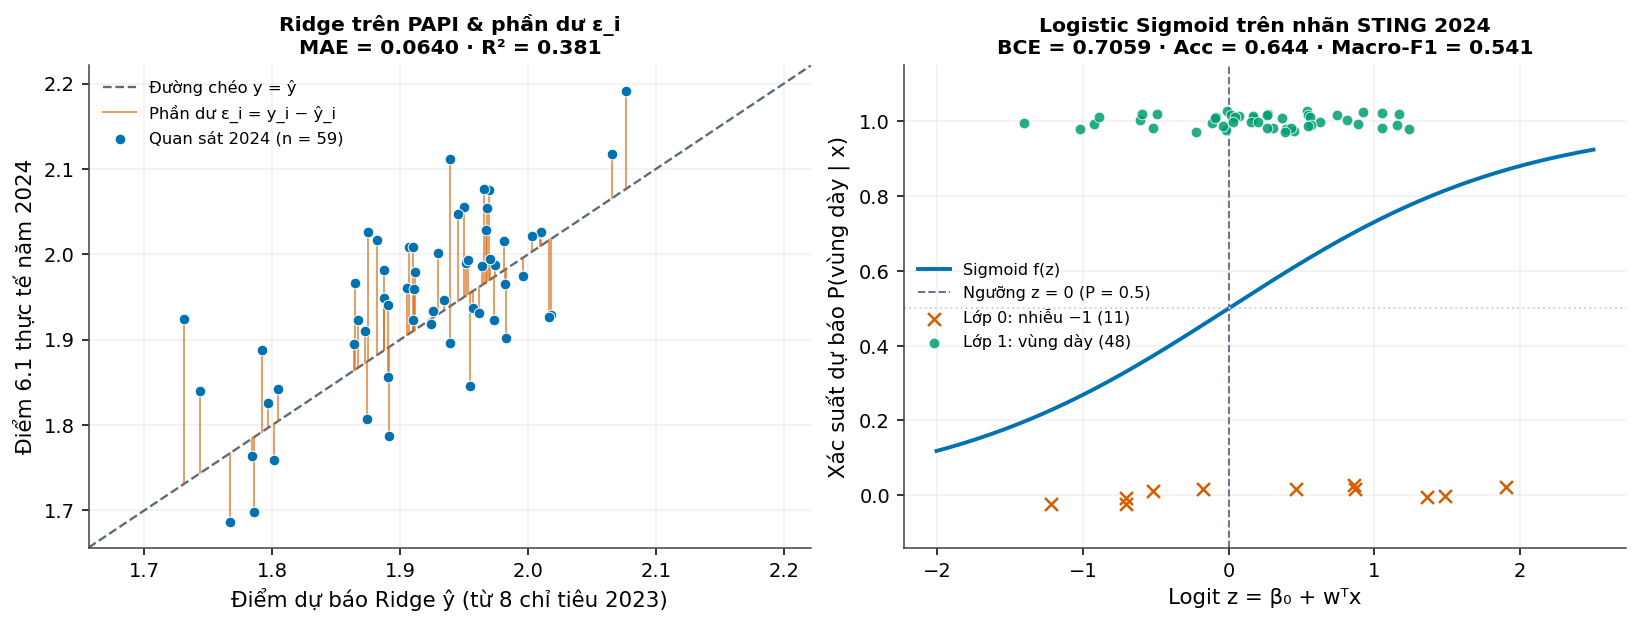

In [5]:
panel = load_panel()
cfg = load_config()
reg_pairs = build_regression_pairs(panel)
hold_reg = reg_pairs[reg_pairs.year_t == 2023]
ridge = joblib.load(ROOT / "models/sup_ridge.joblib")
y_tr_reg = hold_reg["y"].to_numpy()
y_pr_ridge = ridge.predict(hold_reg[REGRESSION_FEATURES].to_numpy())
ridge_mae = float(mean_absolute_error(y_tr_reg, y_pr_ridge))
ridge_r2 = float(r2_score(y_tr_reg, y_pr_ridge))

clf_pairs = build_classification_pairs(panel, cfg["features"], cfg["sting"])
hold_clf = clf_pairs[clf_pairs.year_t == 2023]
clf = joblib.load(ROOT / "models/sup_classifier.joblib")
Xc_te = hold_clf[REGRESSION_FEATURES].to_numpy()
yc_te = hold_clf["y"].to_numpy()
probs_te = clf.predict_proba(Xc_te)[:, 1]
logits_te = clf.decision_function(Xc_te)
preds_te = clf.predict(Xc_te)
bce_papi = float(log_loss(yc_te, probs_te))
acc_papi = float(accuracy_score(yc_te, preds_te))
mf1_papi = float(f1_score(yc_te, preds_te, average="macro", labels=[0, 1], zero_division=0))

print(f"Ridge holdout 2023→2024 (n={len(y_tr_reg)}): MAE={ridge_mae:.4f} | R²={ridge_r2:.3f}")
print(f"Logistic holdout 2023→2024 (n={len(yc_te)}): BCE={bce_papi:.4f} | Acc={acc_papi:.3f} | Macro-F1={mf1_papi:.3f}")

with style_context():
    fig, (ax_r, ax_l) = plt.subplots(1, 2, figsize=(11.6, 4.35), dpi=140, layout="constrained")
    lo = float(min(y_tr_reg.min(), y_pr_ridge.min())) - 0.03
    hi = float(max(y_tr_reg.max(), y_pr_ridge.max())) + 0.03
    ax_r.plot([lo, hi], [lo, hi], "--", color="#5A6B7C", lw=1.2, label="Đường chéo y = ŷ")
    for idx_i, (yt, yp) in enumerate(zip(y_tr_reg, y_pr_ridge, strict=True)):
        ax_r.plot([yp, yp], [yp, yt], "-", color="#D55E00", alpha=0.58, lw=1.05,
                  label="Phần dư ε_i = y_i − ŷ_i" if idx_i == 0 else None)
    ax_r.scatter(y_pr_ridge, y_tr_reg, s=30, color=PALETTE["blue"], edgecolors="white", linewidths=0.5,
                 label="Quan sát 2024 (n = 59)", zorder=3)
    ax_r.set_xlim(lo, hi)
    ax_r.set_ylim(lo, hi)
    ax_r.set_xlabel("Điểm dự báo Ridge ŷ (từ 8 chỉ tiêu 2023)")
    ax_r.set_ylabel("Điểm 6.1 thực tế năm 2024")
    ax_r.set_title(f"Ridge trên PAPI & phần dư ε_i\nMAE = {ridge_mae:.4f} · R² = {ridge_r2:.3f}", fontsize=10.5)
    ax_r.grid(alpha=0.18)
    ax_r.legend(loc="upper left", fontsize=8.4, framealpha=0.92)

    zg = np.linspace(float(logits_te.min()) - 0.6, float(logits_te.max()) + 0.6, 200)
    ax_l.plot(zg, 1.0 / (1.0 + np.exp(-zg)), "-", color=PALETTE["blue"], lw=2.0, label="Sigmoid f(z)")
    ax_l.axvline(0.0, color="#64748B", linestyle="--", lw=1.0, label="Ngưỡng z = 0 (P = 0.5)")
    ax_l.axhline(0.5, color="#CBD5E1", linestyle=":", lw=1.0)
    rng = np.random.default_rng(42)
    m0, m1 = yc_te == 0, yc_te == 1
    ax_l.scatter(logits_te[m0], rng.uniform(-0.03, 0.03, size=int(m0.sum())), s=44, color="#D55E00",
                 marker="x", lw=1.3, label=f"Lớp 0: nhiễu −1 ({int(m0.sum())})", zorder=4)
    ax_l.scatter(logits_te[m1], 1.0 + rng.uniform(-0.03, 0.03, size=int(m1.sum())), s=30, color=PALETTE["green"],
                 alpha=0.85, edgecolors="white", lw=0.45, label=f"Lớp 1: vùng dày ({int(m1.sum())})", zorder=4)
    ax_l.set_ylim(-0.14, 1.15)
    ax_l.set_xlabel("Logit z = β₀ + wᵀx")
    ax_l.set_ylabel("Xác suất dự báo P(vùng dày | x)")
    ax_l.set_title(f"Logistic Sigmoid trên nhãn STING 2024\nBCE = {bce_papi:.4f} · Acc = {acc_papi:.3f} · Macro-F1 = {mf1_papi:.3f}", fontsize=10.5)
    ax_l.grid(alpha=0.18)
    ax_l.legend(loc="center left", fontsize=8.3, framealpha=0.92)
    plt.show()

## Câu hỏi ôn tập về hồi quy

- **Tại sao OLS không đủ cho PAPI mà dùng Ridge?** OLS tối thiểu $\|y - X\beta\|_2^2$; Ridge thêm phạt $L_2$ giúp hệ số ổn định khi 8 chỉ tiêu PAPI tương quan với nhau.
- **Tại sao Ridge giảm MAE nhưng chiếu lên lưới STING vẫn bỏ sót 11/11 tỉnh nhiễu?** Hồi quy ước lượng kỳ vọng có điều kiện $\mathbb{E}[y \mid x]$ nên các giá trị dự báo co về vùng trung tâm — đúng vùng các ô dày STING (cụm lớn 2). Muốn xếp hạng rủi ro rơi vào vùng thưa phải cộng phân bố sai số lịch sử hoặc dùng mô hình phân loại trực tiếp với trọng số lớp cân bằng.